# Assignment 2: training pipeline

You're using a notebook for this stage. If you'd rather use a script,
write `train.py` instead and delete this file. `main.py` refuses to run if
it finds both `train.py` and `train.ipynb`, so exactly one of them must exist.

Replace this cell and everything below it with your own code. When run
via `uv run python main.py train`, this notebook must, start to finish, with no
manual steps in between:

- Get your Roboflow API key via `from api_key import load_api_key`, so that it
  works whether the key is in your `.env` file or in the environment, and
  download your dataset version from Roboflow Universe.
- Finetune yolo11n/yolo11s (or the -cls variant) on that dataset, from the
  pretrained checkpoint.
- Evaluate on the test split against the two baselines named in the brief: the
  pretrained COCO model zero-shot, and a trivial predict-nothing / majority
  class baseline.
- Sweep the confidence threshold, compute the expected cost at each point from
  the cost matrix you defined in REPORT.md, and save the sweep.
- Save everything `app.py` needs to build its dashboard without retraining:
  the metrics, the per-class numbers, the cost sweep, and the chosen operating
  point.

This is your real training pipeline. It takes as long as it takes, and it runs
wherever training is practical for you: your own machine, a GPU you have access
to, or a hosted notebook. Nothing re-runs it to check your submission.

The weights it produces are what you commit to `weights/` and what your app
serves. Say in REPORT.md where you trained and what settings you used.

Save the trained model into `weights/`. That is the file you commit and the
file your app loads.

How you structure the code beyond that is your call to make and be able to
defend: file layout, function boundaries, naming.


In [1]:
# 1. Imports and configuration
import hashlib
import json
import re
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from ultralytics import YOLO

from api_key import load_api_key

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

ROOT = Path.cwd()  # main.py runs this from the repo root
DATA_DIR = ROOT / "datasets" / "pneu-detect-v2"  # gitignored, re-downloaded on demand
WEIGHTS_DIR = ROOT / "weights"  # committed: the model the app serves
ARTIFACTS_DIR = ROOT / "artifacts"  # committed: everything the app needs, so it never retrains
WEIGHTS_DIR.mkdir(exist_ok=True)
ARTIFACTS_DIR.mkdir(exist_ok=True)
WEIGHTS_PATH = WEIGHTS_DIR / "pneumonia_yolo11n_cls.pt"

# The public Roboflow Universe dataset, used as is (not forked)
RF_WORKSPACE = "chestxrayimages"
RF_PROJECT = "pneu-detect"
RF_VERSION = 2

# Training settings
BASE_MODEL = "yolo11n-cls.pt"  # YOLO11 nano classifier, pretrained on ImageNet
EPOCHS = 30
IMGSZ = 224
BATCH = 32
PATIENCE = 10  # stop early if validation accuracy has not improved for this many epochs
SEED = 0

# Classes as named in the export. Positive = pneumonia of either kind.
NEGATIVE_CLASS = "NORMAL"
POSITIVE_CLASSES = ["BACTERIA", "VIRUS"]

# Use a GPU if there is one: CUDA (Colab), Apple Silicon (mps), otherwise CPU
if torch.cuda.is_available():
    DEVICE = 0
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
print(f"Device: {DEVICE}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/Users/leopoldosirolli/Library/Application Support/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Device: mps


In [2]:
# 2. Download the dataset version from Roboflow (skipped if it is already on disk)
def dataset_ready(path: Path) -> bool:
    return all((path / split).is_dir() for split in ["train", "valid", "test"])


if dataset_ready(DATA_DIR):
    print(f"Dataset already downloaded at {DATA_DIR}")
else:
    from roboflow import Roboflow

    rf = Roboflow(api_key=load_api_key())
    version = rf.workspace(RF_WORKSPACE).project(RF_PROJECT).version(RF_VERSION)
    version.download("folder", location=str(DATA_DIR), overwrite=True)

assert dataset_ready(DATA_DIR), f"Expected train/, valid/ and test/ folders in {DATA_DIR}"

# Ultralytics finds the "valid" folder on its own; we call it "val" in our own tables
SPLITS = {"train": DATA_DIR / "train", "val": DATA_DIR / "valid", "test": DATA_DIR / "test"}
CLASSES = sorted(p.name for p in SPLITS["train"].iterdir() if p.is_dir())
print("Classes found:", CLASSES)
assert set(CLASSES) == {NEGATIVE_CLASS, *POSITIVE_CLASSES}, "Class folders differ from what the config expects"

loading Roboflow workspace...
loading Roboflow project...
Exporting format folder in progress : 95.0%
Version export complete for folder format



Extracting Dataset Version Zip to /Users/leopoldosirolli/daiist-assignment-2/datasets/pneu-detect-v2 in folder:: 100%|██████████| 5216/5216 [00:00<00:00, 8690.62it/s]


Classes found: ['BACTERIA', 'NORMAL', 'VIRUS']


In [3]:
# 3. Describe the dataset before training on it
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}


def list_images(split_dir: Path) -> list[Path]:
    return sorted(p for p in split_dir.rglob("*") if p.suffix.lower() in IMAGE_EXTENSIONS)


def patient_id(filename: str) -> str | None:
    """Patient identifier from the original filename, which Roboflow keeps as a prefix.

    person1952_bacteria_4883_jpeg.rf.xxx.jpg -> person1952
    IM-0115-0001_jpeg.rf.xxx.jpg             -> IM-0115
    NORMAL2-IM-0645-0001_jpeg.rf.xxx.jpg     -> NORMAL2-IM-0645
    """
    match = re.match(r"(person\d+)_", filename) or re.match(r"((?:NORMAL2-)?IM-\d+)-", filename)
    return match.group(1) if match else None


records = []
for split, split_dir in SPLITS.items():
    for path in list_images(split_dir):
        records.append({
            "split": split,
            "true_class": path.parent.name,
            "file": path.name,
            "path": str(path.relative_to(DATA_DIR)),
            "patient": patient_id(path.name),
            "md5": hashlib.md5(path.read_bytes()).hexdigest(),
        })
images = pd.DataFrame(records)

# Images per class and split
counts = pd.crosstab(images["true_class"], images["split"])[["train", "val", "test"]]
counts["total"] = counts.sum(axis=1)
counts.loc["total"] = counts.sum()
print("Images per class and split:\n", counts, "\n")
shares = pd.crosstab(images["true_class"], images["split"], normalize="columns")[["train", "val", "test"]].round(3)
print("Class shares within each split:\n", shares, "\n")

# Image sizes (one image = one whole chest X-ray, so there is no object size to report)
sizes = images.groupby("split").head(50).apply(lambda r: Image.open(DATA_DIR / r["path"]).size, axis=1)
print("Image sizes in a sample of 50 per split:", sizes.value_counts().to_dict(), "\n")

# Leakage check 1: the same child appearing in more than one split
with_id = images.dropna(subset=["patient"])
train_patients = set(with_id.loc[with_id["split"] == "train", "patient"])
leak = {}
for split in ["val", "test"]:
    part = with_id[with_id["split"] == split]
    shared = part["patient"].isin(train_patients)
    leak[split] = {"images": int(len(part)), "images_whose_patient_is_in_train": int(shared.sum()),
                   "share": round(float(shared.mean()), 3) if len(part) else 0.0}
print("Patient overlap with train:", leak)
print("Images with no recognisable patient id:", int(images["patient"].isna().sum()))

# Leakage check 2: byte-identical files in more than one split
dupes = images.groupby("md5")["split"].agg(lambda s: sorted(set(s)))
cross_split_dupes = dupes[dupes.apply(len) > 1]
print("Identical files appearing in more than one split:", len(cross_split_dupes))

dataset_stats = {
    "roboflow": {"workspace": RF_WORKSPACE, "project": RF_PROJECT, "version": RF_VERSION},
    "classes": CLASSES,
    "counts": counts.to_dict(),
    "shares": shares.to_dict(),
    "image_sizes_sample": {str(k): int(v) for k, v in sizes.value_counts().items()},
    "patients_total": int(with_id["patient"].nunique()),
    "images_without_patient_id": int(images["patient"].isna().sum()),
    "patient_overlap_with_train": leak,
    "cross_split_identical_files": int(len(cross_split_dupes)),
}
(ARTIFACTS_DIR / "dataset_stats.json").write_text(json.dumps(dataset_stats, indent=2))

Images per class and split:
 split       train   val  test  total
true_class                          
BACTERIA     1746   516   258   2520
NORMAL        925   280   143   1348
VIRUS         961   265   120   1346
total        3632  1061   521   5214 

Class shares within each split:
 split       train    val   test
true_class                     
BACTERIA    0.481  0.486  0.495
NORMAL      0.255  0.264  0.274
VIRUS       0.265  0.250  0.230 

Image sizes in a sample of 50 per split: {(640, 640): 150} 

Patient overlap with train: {'val': {'images': 1061, 'images_whose_patient_is_in_train': 610, 'share': 0.575}, 'test': {'images': 521, 'images_whose_patient_is_in_train': 293, 'share': 0.562}}
Images with no recognisable patient id: 0
Identical files appearing in more than one split: 0


1303

In [4]:
# 4. Finetune the pretrained classifier
model = YOLO(BASE_MODEL)
model.train(
    data=str(DATA_DIR),
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    patience=PATIENCE,
    seed=SEED,
    deterministic=True,
    device=DEVICE,
    fliplr=0.0,  # no mirror images: a chest X-ray is not left-right symmetric (the heart sits on the left)
    workers=0,  # load data in the main process: avoids multiprocessing issues when main.py runs this as a script
    project=str(ROOT / "runs"),
    name="pneumonia-cls",
    exist_ok=True,
)

# Keep the best epoch (by validation accuracy) as the model we ship
shutil.copy(model.trainer.best, WEIGHTS_PATH)
shutil.copy(Path(model.trainer.save_dir) / "results.csv", ARTIFACTS_DIR / "training_history.csv")
train_config = {
    "base_model": BASE_MODEL, "epochs_max": EPOCHS, "imgsz": IMGSZ, "batch": BATCH,
    "patience": PATIENCE, "seed": SEED, "device": str(DEVICE), "fliplr": 0.0,
    "torch": torch.__version__, "weights": str(WEIGHTS_PATH.relative_to(ROOT)),
}
(ARTIFACTS_DIR / "train_config.json").write_text(json.dumps(train_config, indent=2))
print(f"Saved best weights to {WEIGHTS_PATH}")

New https://pypi.org/project/ultralytics/8.4.189 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.173 🚀 Python-3.12.14 torch-2.11.0 MPS (Apple M2)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/leopoldosirolli/daiist-assignment-2/datasets/pneu-detect-v2, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=

In [9]:
# 5. Score every validation and test image with the finetuned model
model = YOLO(str(WEIGHTS_PATH))  # reload the shipped weights, exactly what the app will serve
MODEL_CLASSES = [model.names[i] for i in range(len(model.names))]


def predict_split(model: YOLO, split: str) -> pd.DataFrame:
    part = images[images["split"] == split].reset_index(drop=True)
    paths = [str(DATA_DIR / p) for p in part["path"]]
    probs = [r.probs.data.cpu().numpy() for r in model.predict(paths, imgsz=IMGSZ, device=DEVICE, batch=BATCH, stream=True, verbose=False)]
    probs = pd.DataFrame(np.vstack(probs), columns=[f"p_{c}" for c in MODEL_CLASSES])
    out = pd.concat([part[["split", "path", "patient", "true_class"]], probs], axis=1)
    out["pred_class"] = probs.to_numpy().argmax(axis=1)
    out["pred_class"] = out["pred_class"].map(dict(enumerate(MODEL_CLASSES)))
    # One number per image for the pass / review / fail decision: the probability of any pneumonia
    out["score"] = 1.0 - out[f"p_{NEGATIVE_CLASS}"]
    out["is_positive"] = out["true_class"].isin(POSITIVE_CLASSES)
    return out


pred_val = predict_split(model, "val")
pred_test = predict_split(model, "test")
pred_val.to_csv(ARTIFACTS_DIR / "predictions_val.csv", index=False)
pred_test.to_csv(ARTIFACTS_DIR / "predictions_test.csv", index=False)
print(f"Scored {len(pred_val)} validation and {len(pred_test)} test images")

WARNING ⚠️ NMS time limit 2.050s exceeded
Scored 1061 validation and 521 test images


In [6]:
# 6. Per-class evaluation on the test split (predicted class = highest probability)
def evaluate(y_true, y_pred, classes: list[str]) -> dict:
    index = {c: i for i, c in enumerate(classes)}
    cm = np.zeros((len(classes), len(classes)), dtype=int)  # rows = true class, columns = predicted
    for t, p in zip(y_true, y_pred):
        cm[index[t], index[p]] += 1
    per_class = {}
    for i, c in enumerate(classes):
        tp, predicted, actual = cm[i, i], cm[:, i].sum(), cm[i, :].sum()
        precision = tp / predicted if predicted else 0.0
        recall = tp / actual if actual else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        per_class[c] = {"precision": round(float(precision), 3), "recall": round(float(recall), 3),
                        "f1": round(float(f1), 3), "support": int(actual)}
    # Binary view used by the business decision: any pneumonia vs normal
    true_pos = np.isin(y_true, POSITIVE_CLASSES)
    pred_pos = np.isin(y_pred, POSITIVE_CLASSES)
    binary = {
        "pneumonia_recall": round(float((true_pos & pred_pos).sum() / max(true_pos.sum(), 1)), 3),
        "pneumonia_precision": round(float((true_pos & pred_pos).sum() / max(pred_pos.sum(), 1)), 3),
        "normal_recall": round(float((~true_pos & ~pred_pos).sum() / max((~true_pos).sum(), 1)), 3),
    }
    return {
        "accuracy": round(float(np.trace(cm) / cm.sum()), 3),
        "macro_recall": round(float(np.mean([v["recall"] for v in per_class.values()])), 3),
        "per_class": per_class,
        "binary": binary,
        "confusion_matrix": {"classes": classes, "rows_true_cols_pred": cm.tolist()},
    }


finetuned = evaluate(pred_test["true_class"], pred_test["pred_class"], CLASSES)
print("Finetuned model on test, accuracy:", finetuned["accuracy"])
print(pd.DataFrame(finetuned["per_class"]).T)
print("Confusion matrix (rows = true, columns = predicted):")
print(pd.DataFrame(finetuned["confusion_matrix"]["rows_true_cols_pred"], index=CLASSES, columns=CLASSES))

Finetuned model on test, accuracy: 0.82
          precision  recall     f1  support
BACTERIA      0.804   0.857  0.829    258.0
NORMAL        0.979   0.979  0.979    143.0
VIRUS         0.641   0.550  0.592    120.0
Confusion matrix (rows = true, columns = predicted):
          BACTERIA  NORMAL  VIRUS
BACTERIA       221       2     35
NORMAL           1     140      2
VIRUS           53       1     66


In [7]:
# 7. Baselines on the same test split
# (a) Trivial: always predict the most common class in the training set
majority_class = images.loc[images["split"] == "train", "true_class"].value_counts().idxmax()
trivial = evaluate(pred_test["true_class"], [majority_class] * len(pred_test), CLASSES)

# (b) The pretrained model zero-shot. A -cls checkpoint is pretrained on ImageNet's 1,000
# classes, none of which is one of ours. An image counts as one of our classes only if the
# zero-shot label matches it by name; otherwise it falls back to NORMAL, i.e. nothing flagged.
zero_shot_model = YOLO(BASE_MODEL)
test_paths = [str(DATA_DIR / p) for p in pred_test["path"]]
zs_labels = [zero_shot_model.names[int(r.probs.top1)] for r in zero_shot_model.predict(test_paths, imgsz=IMGSZ, device=DEVICE, batch=BATCH, stream=True, verbose=False)]
name_map = {c.lower(): c for c in CLASSES}
zs_pred = [name_map.get(label.lower(), NEGATIVE_CLASS) for label in zs_labels]
zero_shot = evaluate(pred_test["true_class"], zs_pred, CLASSES)
zero_shot["top_imagenet_labels"] = pd.Series(zs_labels).value_counts().head(5).to_dict()

comparison = pd.DataFrame({
    "finetuned yolo11n-cls": {"accuracy": finetuned["accuracy"], "macro recall": finetuned["macro_recall"], **finetuned["binary"]},
    f"trivial (always {majority_class})": {"accuracy": trivial["accuracy"], "macro recall": trivial["macro_recall"], **trivial["binary"]},
    "pretrained zero-shot": {"accuracy": zero_shot["accuracy"], "macro recall": zero_shot["macro_recall"], **zero_shot["binary"]},
}).T
print(comparison)
print("What the zero-shot model thinks the X-rays are:", zero_shot["top_imagenet_labels"])

metrics = {"test": {"finetuned": finetuned, "trivial": trivial, "zero_shot": zero_shot},
           "majority_class": majority_class, "positive_classes": POSITIVE_CLASSES}
(ARTIFACTS_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2))

WARNING ⚠️ NMS time limit 2.050s exceeded
                           accuracy  macro recall  pneumonia_recall  pneumonia_precision  normal_recall
finetuned yolo11n-cls         0.820         0.795             0.992                0.992          0.979
trivial (always BACTERIA)     0.495         0.333             1.000                0.726          0.000
pretrained zero-shot          0.274         0.333             0.000                0.000          1.000
What the zero-shot model thinks the X-rays are: {'radiator': 230, 'water_bottle': 113, 'isopod': 46, 'vault': 31, 'shower_curtain': 19}


3328

In [10]:
# 8. Business assumptions: YOUR numbers, each one justified in REPORT.md
ASSUMPTIONS = {
    "base_rate": 0.165,  # Lipsett et al., Pediatrics 2018: 16.5% of children X-rayed for suspected pneumonia were positive
    "cost_fn": 1400,  # repeat ED visit 246 + 30% chance of admission x 3,804 (Madrid APR-GRD 139, severity 2)
    "cost_fp": 80,  # follow-up GP visit 61 + amoxicillin ~4 + antibiotic-resistance cost ~15 (Shrestha et al. 2018)
    "cost_tp": 65,  # correct treatment: antibiotics + follow-up visit
    "cost_tn": 0,  # healthy child correctly sent home
    "cost_review": 10,  # ~5 min of radiologist time at ~52 EUR/hour incl. social security
    "reviewer_sensitivity": 0.95,  # derived from Elemraid et al. 2014 (first-read radiologists vs expert)
    "reviewer_specificity": 0.75,  # same source: radiologists over-call pneumonia on paediatric films
    "cases_per_day": 30,  # assumed: chest X-rays a day in a large paediatric emergency department
    "minutes_per_review": 5,  # assumed: time to read and report one paediatric chest X-ray
    "reviewer_hours_per_day": 2,  # assumed: radiologist time a day available for this queue
    "reviewers_available": 1,  # one radiologist covering the queue
}
missing = [k for k, v in ASSUMPTIONS.items() if v is None and k != "reviewers_available"]
assert not missing, f"Fill in these assumptions before running: {missing}"
(ARTIFACTS_DIR / "assumptions.json").write_text(json.dumps(ASSUMPTIONS, indent=2))

287

Cheapest single threshold on validation: 0.64
Cost per 1,000 on test at that threshold: EUR 13,875


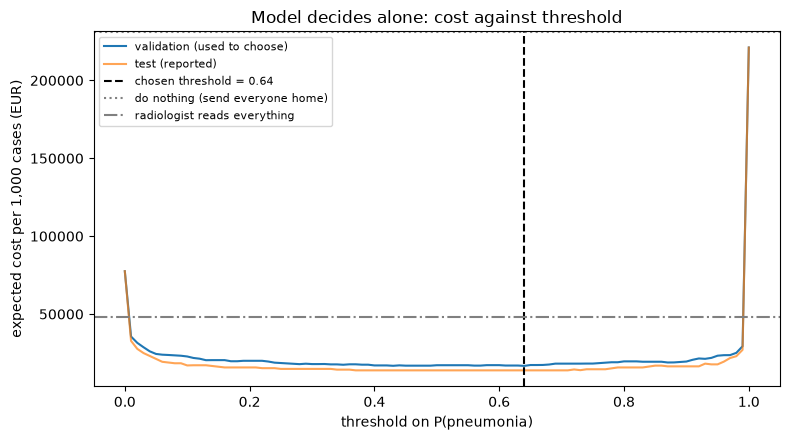

In [11]:
# 9. Cost of being wrong, and the single threshold that minimises it
# The cost formulas live in costing.py so this notebook and the dashboard use the same ones
from costing import CHECK_EVERYTHING, DO_NOTHING, cost_per_1000, outcome_rates, review_share, summarise

THRESHOLDS = np.round(np.arange(0.0, 1.0001, 0.01), 2)
sweep = pd.DataFrame({"threshold": THRESHOLDS})
for name, pred in [("val", pred_val), ("test", pred_test)]:
    rates = [outcome_rates(pred["score"], pred["is_positive"], t, t) for t in THRESHOLDS]
    sweep[f"cost_{name}"] = [cost_per_1000(r, ASSUMPTIONS) for r in rates]
    sweep[f"fn_rate_{name}"] = [r["pos_pass"] for r in rates]  # share of pneumonia sent home
    sweep[f"fp_rate_{name}"] = [r["neg_fail"] for r in rates]  # share of healthy children treated

# Choose on validation, then report on test so the reported number is not tuned on itself
t_single = float(sweep.loc[sweep["cost_val"].idxmin(), "threshold"])
sweep.to_csv(ARTIFACTS_DIR / "cost_sweep.csv", index=False)

do_nothing = cost_per_1000(DO_NOTHING, ASSUMPTIONS)
check_all = cost_per_1000(CHECK_EVERYTHING, ASSUMPTIONS)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(sweep["threshold"], sweep["cost_val"], label="validation (used to choose)")
ax.plot(sweep["threshold"], sweep["cost_test"], label="test (reported)", alpha=0.7)
ax.axvline(t_single, color="black", linestyle="--", label=f"chosen threshold = {t_single:.2f}")
ax.axhline(do_nothing, color="grey", linestyle=":", label="do nothing (send everyone home)")
ax.axhline(check_all, color="grey", linestyle="-.", label="radiologist reads everything")
ax.set_xlabel("threshold on P(pneumonia)")
ax.set_ylabel("expected cost per 1,000 cases (EUR)")
ax.set_title("Model decides alone: cost against threshold")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / "cost_vs_threshold.png", dpi=150)
print(f"Cheapest single threshold on validation: {t_single:.2f}")
print(f"Cost per 1,000 on test at that threshold: EUR {sweep.loc[sweep['threshold'] == t_single, 'cost_test'].item():,.0f}")

In [12]:
# 10. Three outcomes: find the review band (t_low, t_high) that costs least
# If you set reviewers_available, the band may not send more cases than they can read
if ASSUMPTIONS["reviewers_available"] is not None:
    daily_capacity = ASSUMPTIONS["reviewers_available"] * ASSUMPTIONS["reviewer_hours_per_day"] * 60 / ASSUMPTIONS["minutes_per_review"]
    max_review_share = min(1.0, daily_capacity / ASSUMPTIONS["cases_per_day"])
else:
    max_review_share = 1.0

# Try every pair t_low <= t_high on the validation split
rows = []
for i, t_low in enumerate(THRESHOLDS):
    for t_high in THRESHOLDS[i:]:
        rates = outcome_rates(pred_val["score"], pred_val["is_positive"], t_low, t_high)
        rows.append({"t_low": t_low, "t_high": t_high, "cost_val": cost_per_1000(rates, ASSUMPTIONS),
                     "review_share_val": review_share(rates, ASSUMPTIONS)})
band_grid = pd.DataFrame(rows)
feasible = band_grid[band_grid["review_share_val"] <= max_review_share + 1e-9]
best = feasible.loc[feasible["cost_val"].idxmin()]
t_low, t_high = float(best["t_low"]), float(best["t_high"])
band_grid.to_csv(ARTIFACTS_DIR / "band_grid.csv", index=False)

# Price the chosen design against the alternatives, on the test split
alternatives = pd.DataFrame([
    summarise("do nothing (send everyone home)", DO_NOTHING, ASSUMPTIONS),
    summarise("radiologist reads everything", CHECK_EVERYTHING, ASSUMPTIONS),
    summarise(f"model alone (t = {t_single:.2f})", outcome_rates(pred_test["score"], pred_test["is_positive"], t_single, t_single), ASSUMPTIONS),
    summarise(f"model + review band ({t_low:.2f} to {t_high:.2f})", outcome_rates(pred_test["score"], pred_test["is_positive"], t_low, t_high), ASSUMPTIONS),
])
print(f"Review band chosen on validation: pass below {t_low:.2f}, fail at or above {t_high:.2f}")
print(f"Review capacity limit used: {max_review_share:.1%} of cases\n")
print(alternatives.to_string(index=False))

# Test images by true class and outcome
outcome = np.where(pred_test["score"] < t_low, "pass", np.where(pred_test["score"] >= t_high, "fail", "review"))
outcome_table = pd.crosstab(pred_test["true_class"], pd.Categorical(outcome, ["pass", "review", "fail"]), dropna=False, colnames=["outcome"])
print("\nTest images by true class and outcome:\n", outcome_table)

Review band chosen on validation: pass below 0.28, fail at or above 0.98
Review capacity limit used: 80.0% of cases

                            option  cost_per_1000_eur  missed_per_1000  false_alarms_per_1000  review_share  reviews_per_day  radiologists_needed
   do nothing (send everyone home)           231000.0            165.0                    0.0         0.000              0.0                 0.00
      radiologist reads everything            48438.8              8.3                  208.8         1.000             30.0                 1.25
            model alone (t = 0.64)            13874.6              1.3                   17.5         0.000              0.0                 0.00
model + review band (0.28 to 0.98)            13952.1              1.7                    7.3         0.037              1.1                 0.05

Test images by true class and outcome:
 outcome     pass  review  fail
true_class                    
BACTERIA       2       8   248
NORMAL       138   

In [13]:
# 11. Save the operating point for the dashboard
operating_point = {
    "score_definition": f"1 - P({NEGATIVE_CLASS}), i.e. probability of any pneumonia",
    "single_threshold": t_single,
    "t_low": t_low,
    "t_high": t_high,
    "chosen_on": "validation split",
    "max_review_share": max_review_share,
    "alternatives_on_test": alternatives.to_dict(orient="records"),
    "outcome_table_test": {"classes": outcome_table.index.tolist(), "outcomes": ["pass", "review", "fail"], "counts": outcome_table.to_numpy().tolist()},
}
(ARTIFACTS_DIR / "operating_point.json").write_text(json.dumps(operating_point, indent=2))
print("Saved:", sorted(p.name for p in ARTIFACTS_DIR.iterdir()))

Saved: ['assumptions.json', 'band_grid.csv', 'cost_sweep.csv', 'cost_vs_threshold.png', 'dataset_stats.json', 'metrics.json', 'operating_point.json', 'predictions_test.csv', 'predictions_val.csv', 'train_config.json', 'training_history.csv']
